# Zaman Serileri Görselleştirme

Bu derste zaman boyutunu ekliyoruz. Tarihe dayalı verilerde sorular değişir: "ne kadar?" değil, "nasıl değişti?" sorusunu sorarız. COVID-19 salgınının ilk aylarına ait gerçek veriyle çalışacağız: tarihleri doğru biçimde yüklemeyi, kümülatif sayıları günlük artışa çevirmeyi, hareketli ortalama ile gürültüyü yumuşatmayı ve bir bar chart race animasyonu üretmeyi öğreneceksin.

## 🎯 Bu Derste Ne Öğreneceğiz?

Bu dersin sonunda şunları yapabileceksin:

- Tarih sütununu `pd.to_datetime` ile (biçimini belirterek) gerçek tarih türüne çevirmek
- Kümülatif seriyi günlük artışa (`diff`) çevirip doğru soruya cevap vermek
- Hareketli ortalama (`rolling`) ile trend ile gürültüyü ayırmak
- Çok ülkeli zaman serisini karşılaştırmalı çizgi grafiğiyle göstermek
- `FuncAnimation` ile verinin zaman içindeki gelişimini animasyona dönüştürmek

Bu ders, kursun 8. öğrenme çıktısının ilk yarısını karşılıyor.

## 💡 Neden Bu Konuyu Öğreniyoruz?

Satışlar, hava sıcaklığı, döviz kuru, web trafiği, salgın sayıları... Veri dünyasının önemli bölümü zaman damgası taşır. Zaman serisi görselleştirmenin kendine has kuralları vardır: eksen artık sıralanabilir bir kategoriler listesi değil, **zamanın kendisidir**; ve eldeki sayı çoğu zaman birikimlidir (kümülatif), oysa sorular günlük değişimden sorar.

Bu dersteki veri seti, 2020'nin başında COVID-19 vaka sayılarının ülkeler bazında günlük olarak kaydedildiği gerçek bir veri kümesinin küçük bir kesiti: 22 Ocak 2020'den başlayan 112 gün. Veri gerçek olduğu için dersin konusu da gerçek: salgın nasıl büyüdü, hangi ülkeler ne zaman öne çıktı?

## 🔗 Ön Bilgi

- [pandas DataFrame](05-Pandas-Dataframe.ipynb): sütun seçme, yeni sütun türetme.
- [Matplotlib Temelleri](07-Matplotlib-Basics.ipynb): çizgi grafiği, başlık, eksen.
- [Matplotlib İleri Düzey](08-Matplotlib-Advanced.ipynb): çok serili grafik + `legend`.

## 🔍 Birlikte Keşfedelim

Veri `../Data/11-corona-data.csv` dosyasında: her satır bir gün, sütunlar ülkeler, hücreler o günkü **toplam (kümülatif)** vaka sayısı. Türkiye'nin serisini çizelim — ama önce tahmin: `date` sütunu yüklenince pandas onu ne sanacak? Tarih mi, metin mi? Tahminini yaz, sonra çiz:

date sütununun türü: str


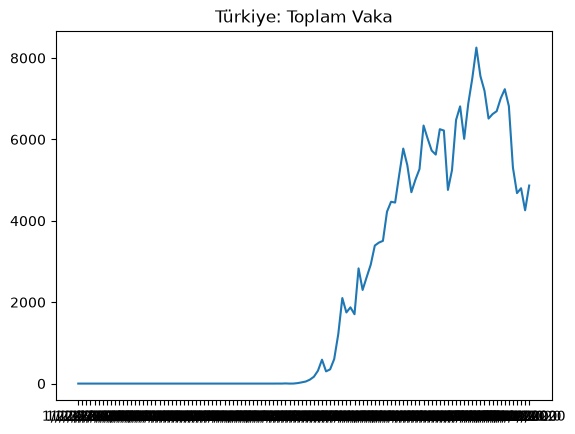

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

corona = pd.read_csv("../Data/11-corona-data.csv")
print("date sütununun türü:", corona["date"].dtype)

plt.plot(corona["date"], corona["Turkey"])
plt.title("Türkiye: Toplam Vaka")
plt.show()

**Gözlem:** İki sorun var. Birincisi çıktıda göründü: `date` sütunu `object` — yani **metin**. pandas, "1/22/2020" yazısının tarih olduğunu bilmiyor. İkincisi grafikte: x eksenine 112 günün metin etiketi sıkıştı; okunmaz ve tarih hesabı da yapılamaz.

Çözüm, tarihleri gerçek tarih türüne çevirmek — biçimi açıkça belirterek:

date sütununun türü: datetime64[us]


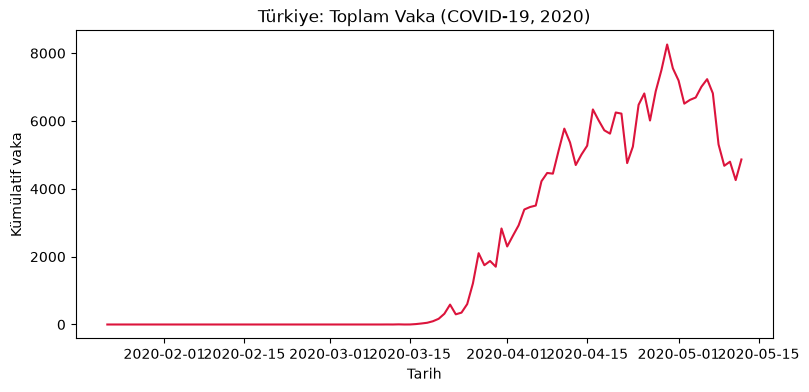

In [2]:
corona["date"] = pd.to_datetime(corona["date"], format="%m/%d/%Y")
print("date sütununun türü:", corona["date"].dtype)

plt.figure(figsize=(9, 4))
plt.plot(corona["date"], corona["Turkey"], color="crimson")
plt.title("Türkiye: Toplam Vaka (COVID-19, 2020)")
plt.xlabel("Tarih")
plt.ylabel("Kümülatif vaka")
plt.show()

**Gözlem:** Eksen artık tarihleri akıllıca yerleştiriyor (ay adlarıyla) ve `dtype` `datetime64[ns]` oldu. `format="%m/%d/%Y"` kalıbı "ay/gün/yıl" demek; verinin tarihleri böyle yazıldığı için bunu açıkça söyledik. Biçimi yanlış söylersen pandas hata verir — ki bu iyidir: sessizce yanlış tarih üretmez.

## 📖 Kavramlar

**Zaman serisi (time series):** Zaman damgası taşıyan ölçümler dizisi. Görselleştirmede x ekseni zamandır; sıra ve aralık anlam taşır.

**Tarih ayrıştırma:** Metin tarihlerin `datetime` türüne çevrilmesi (`pd.to_datetime` + `format`). Tür dönüşünce tarih aritmetiği (aralık seçme, yeniden örnekleme) açılır.

**Kümülatif ve günlük:** Veri setindeki sayılar o güne kadar **toplanan** vakalardır. "Bugün kaç yeni vaka var?" sorusu için kümülatif serinin **ardışık farkını** alırız (`diff`): bugünün değeri eksi dünkü.

**Hareketli ortalama (moving average):** Son n günün ortalamasını kayan pencereyle hesaplar (`rolling(n).mean()`). Günlük dalgalanmaları (hafta sonu bildirim eksikleri gibi) yumuşatır, eğilimi görünür kılar.

**Trend ve gürültü:** Zaman serisinin uzun yönlü bileşenine trend, günlük rastgele dalgalanmalara gürültü denir. Hareketli ortalama, ikisini ayırmanın en basit aracıdır.

## 🛠️ Uygulama

### 1) Ülkeleri karşılaştırmak

Dört ülkenin kümülatif serisini tek grafikte izleyelim:

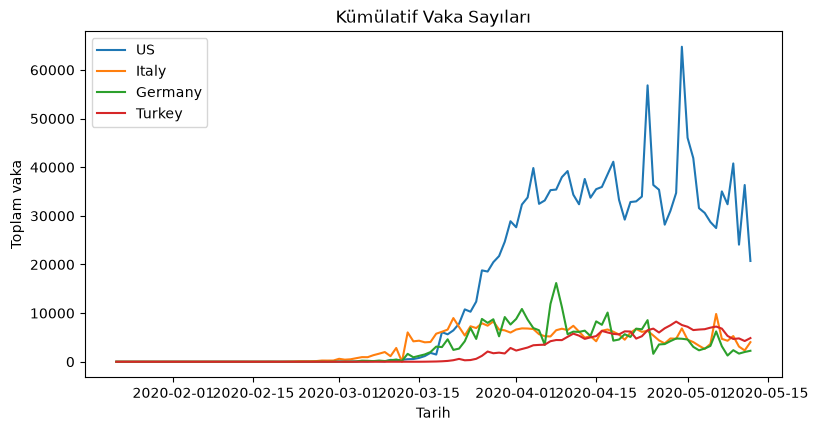

In [3]:
ulkeler = ["US", "Italy", "Germany", "Turkey"]

plt.figure(figsize=(9, 4.5))
for ulke in ulkeler:
    plt.plot(corona["date"], corona[ulke], label=ulke)

plt.title("Kümülatif Vaka Sayıları")
plt.xlabel("Tarih")
plt.ylabel("Toplam vaka")
plt.legend()
plt.show()

**Gözlem:** ABD'nin serisi Mart sonundan itibaren dikey fırlıyor; İtalya ve Almanya daha erken başlayıp daha yatay sürüyor; Türkiye'nin eğrisi sağ altta henüz tırmanışta. 8. dersin çoklu seri + gösterge reçetesi, zaman ekseninde de aynen çalışıyor.

### 2) Kümülatiften günlük artışa

"Her gün kaç yeni vaka?" sorusu için `diff`:

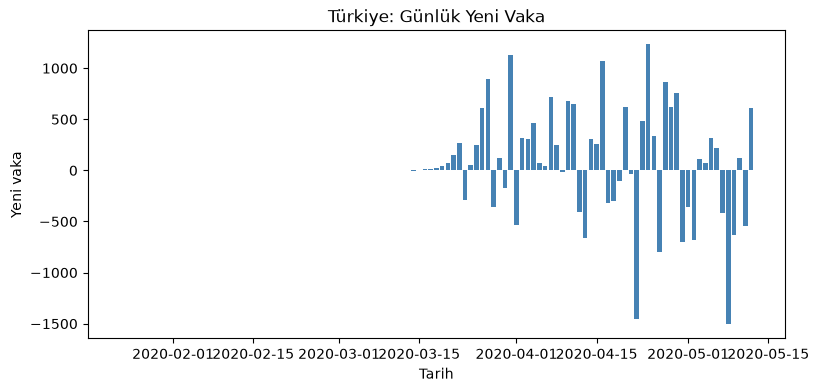

In [4]:
turkiye_gunluk = corona["Turkey"].diff()

plt.figure(figsize=(9, 4))
plt.bar(corona["date"], turkiye_gunluk, color="steelblue")
plt.title("Türkiye: Günlük Yeni Vaka")
plt.xlabel("Tarih")
plt.ylabel("Yeni vaka")
plt.show()

**Gözlem:** Kümülatif eğrinin eğimi burada dikey çubuklara dönüştü: Nisan ortasına doğru günlük artış hızlanıyor. Bir ayrıntı: `diff`'in **ilk satırı NaN**'dır — bir önceki gün olmadığı için ilk günün artışı hesaplanamaz. Bu, 6. dersteki eksik değer konusunun doğal bir varyantı; genelde ilk satırı görmezden gelir ya da `fillna(0)` yaparız.

### 3) Gürültüyü yumuşatmak: hareketli ortalama

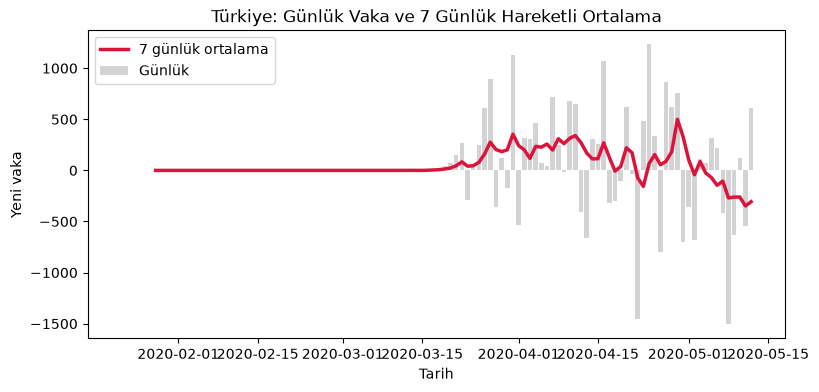

In [5]:
gunluk_dolu = turkiye_gunluk.fillna(0)
ma7 = gunluk_dolu.rolling(7).mean()

plt.figure(figsize=(9, 4))
plt.bar(corona["date"], gunluk_dolu, color="lightgray", label="Günlük")
plt.plot(corona["date"], ma7, color="crimson", linewidth=2.5, label="7 günlük ortalama")
plt.title("Türkiye: Günlük Vaka ve 7 Günlük Hareketli Ortalama")
plt.xlabel("Tarih")
plt.ylabel("Yeni vaka")
plt.legend()
plt.show()

**Gözlem:** Gri çubuklar günlük dalgalanmalarla (raporlama ritmi, hafta sonu boşlukları) titriyor; kırmızı çizgi son yedi günün ortalamasını taşıdığı için eğilimi gösteriyor. Bu ikili, haber sitelerindeki salgın grafiklerinin standart formülüdür: ham veri soluk, hareketli ortalama belirgin.

### 4) Animasyon: bar chart race

Şimdi zaman boyutunu adım adım izleyelim: seçili ülkelerin toplam vaka sıralaması, iki haftada bir alınmış karelerle animasyona dönüşüyor. Hücre çalıştırıldığında altında oynatıcı (play düğmeli) bir animasyon görünür:

In [6]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

yaris_ulkeleri = ["US", "Italy", "Germany", "Spain", "France",
                  "China", "Iran", "United Kingdom", "Turkey", "Russia"]
veri = corona[yaris_ulkeleri]

kareler = list(range(0, len(corona), 14))    # iki haftada bir kare

fig, ax = plt.subplots(figsize=(7, 4.5))

def guncelle(k):
    ax.clear()
    an = veri.iloc[k].sort_values(ascending=True)
    ax.barh(an.index, an.values, color="steelblue")
    ax.set_title(f"Toplam vaka — {corona['date'].iloc[k].strftime('%d.%m.%Y')}")
    ax.set_xlabel("Kümülatif vaka")

anim = FuncAnimation(fig, guncelle, frames=kareler, interval=500)
plt.close(fig)
HTML(anim.to_jshtml())

Animasyonun mantığı: `FuncAnimation` verirken bir `guncelle` fonksiyonu ve kare listesi veriyoruz; her karede fonksiyon çalışıp o günün sıralamasını çubuk grafik olarak yeniden çiziyor. `to_jshtml()` sonucu, tarayıcıda çalışan küçük bir oynatıcıya çeviriyor.

> **Not:** Bu animasyon, defteri GitHub'da gezen bir okuyucuya görünmez; GitHub defterlerdeki JavaScript çıktılarını göstermez. Animasyonu görmek için defteri kendi ortamında (ya da Colab'da) çalıştırman gerekir. GitHub okuyucusu için son kareyi statik grafik olarak da bırakalım:

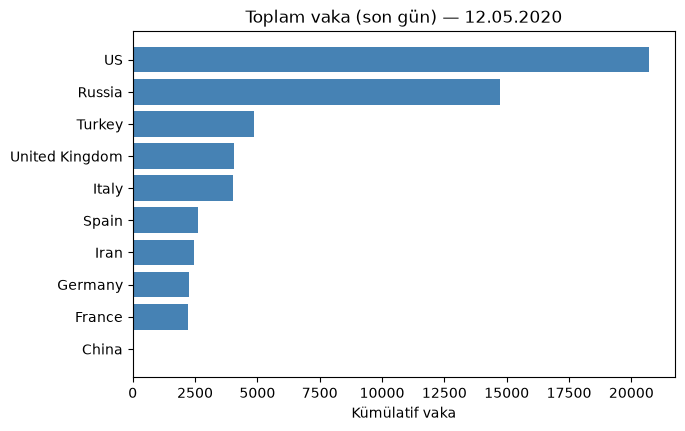

In [7]:
son_gun = veri.iloc[-1].sort_values()

plt.figure(figsize=(7, 4.5))
plt.barh(son_gun.index, son_gun.values, color="steelblue")
plt.title(f"Toplam vaka (son gün) — {corona['date'].iloc[-1].strftime('%d.%m.%Y')}")
plt.xlabel("Kümülatif vaka")
plt.show()

### 5) Kodu tamamla (TODO)

In [8]:
# TODO: İtalya'nın günlük yeni vaka serisini hesapla ve
# 7 günlük hareketli ortalama eşliğinde çiz.
# İpucu: Yukarıdaki Türkiye akışını İtalya sütununa uyarla.

# italya_gunluk = ...
# italya_ma = ...
# plt.bar(...), plt.plot(...), plt.legend(), plt.show()

print("Kontrol: İtalya toplam (son gün):", corona['Italy'].iloc[-1])

Kontrol: İtalya toplam (son gün): 4026


Çözüm "Cevaplar" bölümünde.

## 🧪 Deneyelim ve Gözlemleyelim

**Deney 1:** Hareketli ortalama penceresini değiştir: `rolling(3)` ve `rolling(30)` ile aynı grafiği çiz. Pencere küçüldükçe ve büyüdükçe çizgi nasıl davranıyor? 3 günlük ortalama hangi sorunları çözemiyor, 30 günlük ortalamada ne kayboluyor?

**Deney 2:** Logaritmik eksen. Kümülatif karşılaştırma grafiğine `plt.yscale("log")` ekle. Değişim ne? (İpucu: logaritmik eksende sabı hızlı büyüme, düz doğru olarak görünür; ülkelerin büyüme hızları böyle karşılaştırılır. Efsane sorunları: sıfır değerler log eksende çizilemez.)

**Deney 3:** Tarih biçimini yanlış söyle: `pd.to_datetime(corona["date"].astype(str), format="%d/%m/%Y")` dene ve hata mesajını oku. pandas neden "tam tarihlerle eşleşmedi" diyor? Doğru kalıbı bulup tekrar çevir.

## 🧯 Bir Şeyler Ters Giderse

| Belirti | Olası neden | Çözüm |
|---|---|---|
| `ValueError: time data ... doesn't match format` | `format` kalıbı verideki yazımla uyuşmuyor | Örnek bir değere bak ("1/22/2020" → `%m/%d/%Y`); kalıbı düzelt |
| `diff()` sonrası ilk satır `NaN` | Bir önceki gün yok; davranış normal | `fillna(0)` ya da ilk satırı yok say |
| `rolling(n)` başında `NaN` değerler | Pencere dolmadan ortalama hesaplanamaz | Normaldir; pencere dolduktan sonraki değerler anlamlıdır |
| X ekseni etiketleri üst üste | Tarihler metin olarak kaldı | `pd.to_datetime` ile çevir; matplotlib tarihleri otomatik yerleştirir |
| Animasyon çok yavaş/çok büyük | Kare sayısı çok ya da `interval` küçük | Kareleri seyrelt (`range(0, n, adım)`), `interval`'ı büyüt |
| `KeyError: 'Turkiye'` | Ülke adı sütunla birebir değil | `list(corona.columns)` ile gerçek adlara bak ("Turkey", "United Kingdom"...) |

> **İpucu:** Zaman serisi işlemede ilk kontrol her zaman `df["tarih"].dtype` olsun: `object` görüyorsan daha işin başındasın; `datetime64` görmeden tarih aritmetiği (aralık seçme, örnekleme, hareketli ortalama) yapılmaz.

## 🏋️ Kendin Dene

1. **İki ülke, bir grafik:** Almanya ve İtalya'nın **günlük** yeni vaka serilerini 7 günlük hareketli ortalamalarıyla aynı grafikte karşılaştır. Hangi ülke hangi haftada zirve yaptı?
2. **İran analizi:** İran'ın kümülatif serisini çiz; sonra günlük artışına çevir. Kümülatifte "düzleşme" gözün neresinde başlıyor?
3. **Anlat:** Yaptığın iki grafiği bir arkadaşına göstermeden önce "bu grafik ne anlatıyor?" sorusuna tek cümlelik cevap hazırla. Cevabın "sayı arttı" değil, "ne zaman ve ne kadar hızla arttı" içersin.


## 🧠 Öğrendiklerini Kontrol Et

Cevaplar defterin sonundaki "Cevaplar" bölümünde. Önce kendin dene.

1. `pd.read_csv` sonrası `date` sütunu `object` türünde çıktı. Bu ne demektir ve neden sorun olur?
2. Veri kümülatif vaka sayıları içeriyor. "Dün kaç yeni vaka oldu?" sorusunu hangi işlemle yanarlarsın? İlk satır neden NaN olur?
3. Hareketli ortalama neyi yumuşatır, neyi korur? 7 günlük pencere neden özellikle anlamlıdır?
4. Bar chart race animasyonunda bir "kare" neyi temsil eder; `interval` parametresi neyi kontrol eder?
5. Bu animasyon GitHub defter önizlemesinde neden görünmez? Ne yapılabilir?
6. Trend ile gürültüyü bir cümleyle tanımla ve hangisinin hangi araçla görünür yapıldığını söyle.

## 🚀 Bağımsız Çalışma

- **Kendi zaman serin:** Kendi hayatından bir zaman serisi topla (örneğin bir hafta boyunca günlük telefon ekran süresi, adım sayısı ya da kahve tüketimin). Küçük bir CSV'ye yaz, yükle, tarihleri ayrıştır, günlük değerleri ve 3 günlük hareketli ortalamayı çiz.
- **Mevsimsellik araştırması:** "Mevsimsellik (seasonality)" kavramını araştır: aylık dondurma satışları ya da elektrik tüketimi gibi örneklerde yıl içinde tekrarlanan örüntü neye benzer? Bu dersteki 112 günlük veride mevsimsellik bekler miydin?

## 📚 Daha Fazlasını Öğrenmek

- pandas zaman serisi rehberi: https://pandas.pydata.org/docs/user_guide/timeseries.html
- matplotlib animasyon API'si: https://matplotlib.org/stable/api/animation_api.html

İngilizcedir; kodlar doğrudan çalıştırılabilir.

## ✅ Kısa Özet

- Zaman serisinde x ekseni zamandır; tarihler `pd.to_datetime(..., format=...)` ile gerçek tarih türüne çevrilmelidir.
- Kümülatif seri "toplamı", ardışık fark (`diff`) "günlük değişimi" verir; ilk satır doğal olarak NaN olur.
- Hareketli ortalama (`rolling(n).mean()`) gürültüyü yumuşatır, trendi görünür kılar; pencere büyüklüğü bir tasarım kararıdır.
- Çok ülkeli karşılaştırma = çok serili çizgi + gösterge; logaritmik eksen büyüme hızlarını karşılaştırır.
- `FuncAnimation` + `to_jshtml()` verinin zaman içindeki gelişimini oynatıcıya çevirir; GitHub önizlemesi animasyonu göstermez, statik kare gerekir.

Sıradaki derste grafiklerimiz etkileşimli hâle geliyor: plotly ile üzerine gelince değer gösteren, yakınlaştırılabilen grafikler üreteceğiz.

---

[← Önceki ders: Seaborn İleri Düzey](10-Seaborn-Advanced.ipynb) · [Sıradaki ders: Etkileşimli Grafikler: plotly →](12-Interactive-Plots.ipynb)

## Cevaplar

### Uygulama 5: İtalya günlük serisi (TODO çözümü)

```python
italya_gunluk = corona["Italy"].diff().fillna(0)
italya_ma = italya_gunluk.rolling(7).mean()

plt.figure(figsize=(9, 4))
plt.bar(corona["date"], italya_gunluk, color="lightgray", label="Günlük")
plt.plot(corona["date"], italya_ma, color="crimson", linewidth=2.5, label="7 günlük ortalama")
plt.title("İtalya: Günlük Vaka ve Hareketli Ortalama")
plt.xlabel("Tarih")
plt.ylabel("Yeni vaka")
plt.legend()
plt.show()
```

### Kontrol Et 1

Sütunun pandas için sıradan metin olduğu anlamına gelir. Sorun: tarih aritmetiği yapılamaz (aralık seçme, sıralama garantisi, yeniden örnekleme), eksende 112 ayrı metin etiketi sıkışır ve matplotlib tarihleri akıllıca yerleştiremez.

### Kontrol Et 2

Ardışık farkla: `corona["Turkey"].diff()` — her günün değeri bir önceki günün değerinden çıkarılır. İlk satır NaN olur çünkü ilk günden önce bir gün yoktur; fark tanımsızdır.

### Kontrol Et 3

Günlük rastgele dalgalanmaları (raporlama ritmi, hafta sonu atlamaları) yumuşatır; serinin uzun yönlü eğilimini (trend) korur. 7 günlük pencere anlamlıdır çünkü bir haftalık döngüsel ritmi (hafta içi/hafta sonu) tam bir pencereye sığdırıp ortalar.

### Kontrol Et 4

Bir kare, listedeki bir günün (bizde 14 günlük adımlarla) o anki verisinin çizilmiş görüntüsünü temsil eder. `interval` kareler arasındaki süreyi (milisaniye) kontrol eder; büyütdükçe animasyon yavaşlar.

### Kontrol Et 5

Çünkü animasyon çıktısı tarayıcıda çalışan JavaScript'tir ve GitHub defter önizlemesi JavaScript çıktılarını güvenlik nedeniyle çalıştırmaz. Çözüm: GitHub okuyucusu için son karenin (ya da birkaç önemli karenin) statik grafiğini deftere gömmek; animasyonu görmek isteyen defteri kendi ortamında çalıştırır.

### Kontrol Et 6

Trend, serinin uzun vadeli yönüdür; gürültü, günlük rastgele dalgalanmalardır. Trend hareketli ortalama ile, gürültü ham günlük değerlerle görünür kılınır.

### İpuçları

**Kendin Dene:** Günlük seri için `corona["Germany"].diff()` ve `corona["Italy"].diff()`; hareketli ortalama için `.fillna(0).rolling(7).mean()`. Zirve haftasını bulmak için hareketli ortalamanın en büyük değerinin hangi tarihte olduğunu `idxmax()` ile bulabilirsin.
